# News Headline Dataset for Sarcasm Detection

This notebook makes use of the News Headline Dataset for Sarcasm Detection, published on Kaggle. Instead of Tweets, it is made of headlines from online newspapers, such as The Onion, known to be a satirical newspaper, and the Huffpost, a more traditional newspaper. [More about the dataset.](https://www.kaggle.com/rmisra/news-headlines-dataset-for-sarcasm-detection)[1]. 

The associated task is thus to build a model to detect sarcasm. 


## Detecting sarcasm in headlines

### What is sarcasm? 

Before going any further, it is interesting to define clearly what sarcasm is. Lexico, the Oxford University Press dictionary, defines it as `"The use of irony to mock or convey contempt"`(a)[2]. While we get the idea that sarcasm involves humour, we don't learn much from this definition.   

The OUP definition of irony is as follows:   

`"The expression of one's meaning by using language that normally signifies the opposite, typically for humorous or emphatic effect"`(b)   

and more specifically, in our case:   

`"A state of affairs or an event that seems deliberately contrary to what one expects and is often wryly amusing as a result."` (c)[3]  

This last definition seems to fit rather well the content of satirical newspapers such as the Onion, the articles of which make the bulk of the sarcastic headlines. Let's look at an example from the Onion (found in the corpus): 

- mother comes pretty close to using word 'streaming' correctly [*(article)*](https://www.theonion.com/mother-comes-pretty-close-to-using-word-streaming-cor-1819575546)

Looking at the first two words, I personnaly would expect something about a mother doing something really wrong (like killing her child) or really brave (saving children from fire), or maybe something happened to her (died in a car crash or was saved by a 5-year old), because that's a typical headline for miscenallaneous news items. However, the Onion headline goes against my expectations and makes fun of the fact that "older" people have a hard time keeping up with trendy and techy things, here 'streaming'. It is both **unexpected** and **amusing**, at least for someone my age, in their twenties, thus fitting perfectly the definition (c) provided by the OUP. It is also designed to mock (a) older people's difficulties to follow and use new words , slang or technologies name properly. However, it can be seen as closer to satire than sarcasm, as there is no obvious opposite meaning to that sentence (b), as opposed to `"I love waiting long hours in the doctor office"` for instance.

A non-sarcastic headline, also from the corpus, that is somewhat similar to the previous example is:

- father of muslim american war hero to trump: 'you have sacrificed nothing' [*(article)*](https://www.huffpost.com/entry/khizr-khan-trump-muslim_n_579aaf63e4b08a8e8b5d7973)

It also starts with a parent doing something, here the father addresses the US president after his son died in the army. The tone is more serious, more solemn, in line with the events at the time. It is also pretty common in traditional newspapers to find citizens addressing politicians, especially presidents, after a big event, such as the death of a soldier. There is nothing unexpected about this headline, and there is nothing funny either, since the father points out Trump's inability to pay his respects to Muslim citizens - and more generally immigrants - who sacrificed their lives in the line of duty.

Now, for analylitic purposes later on, I would go even one step further: not only are we dealing with sarcasm, but we are also dealing with satire. According to the definition of satire in journalism provided by the University of South Carolina (see below), satirical news makes use of sarcasm and parody, amongst others literary tools, to comment upon news items, often involving individuals. 

`"Parody (or spoofs), sarcasm, exaggeration, and analogy are defining literary tools of satire that help create its humorous tone. In journalism, satire most commonly pokes fun at the news or uses parody portrayed as conventional news. While satirical news is defined by its comedic nature, using deadpan humor to create what is called “fake news,” its underlying objective is to make statements about real people, events, and trends, often with the intent of influencing change."`[4]

To that, we may add the notion of scorn, that is traditionally found in satire[5]. 

With that in mind, we have a pretty good understanding of what sarcasm and satire are: (scornful) humour as a way to convey a critical message about a news item or society in general, with the intent to influence readership. Let's begin. 

### Imports and loading the dataset

First, we start by importing necessary libraries.

We'll use:
- `spacy` to tokenize the headlines for analytics purposes 
- `collections` and `wordcloud` to build wordclouds of the most common tokens in both neutral and sarcastic headlines
- `keras`, `numpy` and `pandas` to build the model, including the preprocessing of the dataset. 
- `matplotlib` is used both to display the evolution of metrics during training and the wordclouds
- `tqdm` and `time` are only used to monitor the tokenization task with spaCy, since it takes 2 minutes on average to perform.

*This notebook was originally run with a mounted virtual environment. If you do not wish to mount a virtual environment to your jupyter server, simply run the code below (tqdm is required by spacy, so there should be no need to pip install it)*

> !pip install keras numpy pandas spacy wordcloud matplotlib  
!python -m spacy download "en_core_web_sm"

In [1]:
import re
import time
import warnings
import spacy
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
from collections import Counter
from statistics import mean
from keras.callbacks import EarlyStopping
from keras.layers import Bidirectional, Dense, Embedding, Flatten,\
                         Input, LSTM, Dropout, GlobalAveragePooling1D
from keras.models import Sequential
from keras.preprocessing.text import Tokenizer
from keras.preprocessing.sequence import pad_sequences
from tqdm import tqdm
from wordcloud import WordCloud

warnings.filterwarnings('ignore')

Next, we read the dataset with pandas. We get rid of the articles' urls because they are not useful for the task at hand and we remove duplicates.

In [2]:
sarcasm_dataframe = pd.read_json(path_or_buf='input/Sarcasm_Headlines_Dataset_v2.json', dtype={
                                            'is_sarcastic': 'int', 
                                            'headline': 'object',
                                            'article_link': 'object'
                                          })

sarcasm_dataframe = sarcasm_dataframe.drop(columns='article_link')
sarcasm_dataframe = sarcasm_dataframe.drop_duplicates().dropna(how='any')
sarcasm_dataframe.head(15)

,is_sarcastic,headline
0,1,thirtysomething scientists unveil doomsday clo...
1,0,dem rep. totally nails why congress is falling...
2,0,eat your veggies: 9 deliciously different recipes
3,1,inclement weather prevents liar from getting t...
4,1,mother comes pretty close to using word 'strea...
5,0,my white inheritance
6,0,5 ways to file your taxes with less stress
7,1,richard branson's global-warming donation near...
8,1,shadow government getting too large to meet in...
9,0,lots of parents know this scenario


Now, we remove stopwords from the headlines. Because we use spacy to tokenize and because there are over 28.000 headlines, it can take a while (on average 2 minutes). To measure the advancement, we'll use tqdm loading bar. 

## Analysis

While we are here, we are going to perform a few analysis on the dataset.

- in `filtered_tokens`, we only remove tokens whose POS is either SYM or PUNCT in addition to the existing stopwords (see the full in the stopwords.txt file). 
- `filtered_lemmas` is the same as `filtered_tokens`, but instead of considering the actual tokens, we are considering their lemmas.  

These two lists will be used to compare the results of the models: with no processing what so ever (punctuation marks and stopwords are not removed), with basic processing (no punctuation marks and without stopwords), and with the lemmas, to see which perform better. I would expect the first two to perform at least slightly better than the lemmatized one, because we might lose some important features of sarcasm with the lemmatization.

- in `tokens_*`, which is later used to build the word clouds, we also remove words whose POS is a preposition or an auxiliary. 

The `tokens_*` are divided in several lists: 
- `tokens_sarcastic` dedicated to tokens found in sarcastic headlines
- `tokens_neutral` dedicated to neutral headlines
- `adjectives_sarcastic` dedicated to adjectives in sarcastic headlines
- `adjectives_neutral` dedicated to adjectives in neutral headlines
- `nouns_sarcastic` dedicated to nouns and proper nouns in sarcastic headlines
- `nouns_neutral` dediecated to nouns and proper nouns in neutral headlines  
- `adverbs_sarcastics` dedicated to adverbs in sarcastic headlines
- `adverbs_neutrla` dedicated to adverbs in neutral headlines

This way, we can see which words are most common in each category, but also analyse the different usage of adjectives depending on the "polarity" of the headline, as well as the most discussed "topics" so to speak. For these lists, we'll use the lemmas. 

I expect that satirical newspapers will make extensive use of adjectives and adverbs, at least more than traditional newspapers. Note that there is slightly more traditional headlines than sarcastic ones (14.984 *vs* 11.725). 

**Note**: _we're using spacy `Token.tag_` attribute and not the `Token.pos_` attribute. These are more detailed POS tags, based on the [Penn Treebank POS tag scheme](https://www.ling.upenn.edu/courses/Fall_2003/ling001/penn_treebank_pos.html)._ 

**Note**: "neutral" and "traditional" are used interchangeably throughout the notebook, and so are "satirical" and "sarcastic".

In [86]:
# Load the custom stopwords list
with open('utils/stopwords.txt', 'r', encoding='utf-8') as file: 
    stopwords = file.readlines()
    stopwords = [word.strip() for word in stopwords]

#convert the dataframe into two distinct lists
headline_tmp = list(sarcasm_dataframe.headline)
is_sarcastic = list(sarcasm_dataframe.is_sarcastic)

nlp = spacy.load("en_core_web_sm")


headlines_lemmas = []
headlines_tokens = []
tokens_sarcastic = []
tokens_neutral = []
adjectives_sarcastic = []
adjectives_neutral = []
adverbs_neutral = []
adverbs_sarcastic = []
nouns_sarcastic = []
nouns_neutral = []


unwanted_tokens = ['is', 'are', 'have', 'has', 'had', 'was', 'were', '\'s', 'n\'t', '-', '.', '%']
unwanted_pos = ['IN', 'RP', 'POS', 'PRP', 'CC', 'CD']

start_time = time.time()

for i in tqdm(range(len(headline_tmp))):
    sentence = headline_tmp[i]
    nlp_sentence = nlp(sentence)
    filtered_lemmas = []
    filtered_tokens = []
    
    for token in nlp_sentence:
        if token.pos_ not in ["SYM", "PUNCT", ".", 'DET']:
            if token.text not in stopwords and token.text not in unwanted_tokens:
                filtered_lemmas.append(token.lemma_)
                filtered_tokens.append(token.text)

                if token.tag_ not in  unwanted_pos and token.text not in unwanted_tokens:
                    if is_sarcastic[i] == 1:
                        tokens_sarcastic.append(token.lemma_)
                        if token.tag_.startswith('JJ'):
                            adjectives_sarcastic.append(token.lemma_)
                        if token.tag_.startswith('NN'):
                            nouns_sarcastic.append(token.lemma_)
                        if token.tag_.startswith('RB'):
                            adverbs_sarcastic.append(token.lemma_)
                    else: 
                        tokens_neutral.append(token.text)
                        if token.tag_.startswith('JJ'):
                            adjectives_neutral.append(token.lemma_)
                        if token.tag_.startswith('NN'):
                            nouns_neutral.append(token.lemma_)
                        if token.tag_.startswith('RB'):
                            adverbs_neutral.append(token.lemma_)
    
    joined_sentence = ' '.join(word for word in filtered_lemmas)
    joined_sentence = re.sub(r"( 's\b|\w*' s\b)", "'s", joined_sentence)
    joined_sentence = re.sub(r"\s{2,}", " ", joined_sentence)
    headlines_lemmas.append(joined_sentence)
    
    joined_sentence = ' '.join(word for word in filtered_tokens)
    joined_sentence = re.sub(r"( 's\b|\w*' s\b)", "'s", joined_sentence)
    joined_sentence = re.sub(r"\s{2,}", " ", joined_sentence)
    headlines_tokens.append(joined_sentence)

end_time = (time.time() - start_time)/60
print(f"Tokenization took {end_time:.2f} minute(s).")

sarcasm_dataframe['headline_lemmas'] = headlines_lemmas
sarcasm_dataframe['headline_tokens'] = headlines_tokens
sarcasm_dataframe.head(15)

100%|██████████| 28503/28503 [02:24<00:00, 197.32it/s]

Tokenization took 2.41 minute(s).


,is_sarcastic,headline,headline_lemmas,headline_tokens
0,1,thirtysomething scientists unveil doomsday clo...,thirtysomething scientist unveil doomsday cloc...,thirtysomething scientists unveil doomsday clo...
1,0,dem rep. totally nails why congress is falling...,dem rep totally nail congress fall short gende...,dem rep totally nails congress falling short g...
2,0,eat your veggies: 9 deliciously different recipes,eat veggie 9 deliciously different recipe,eat veggies 9 deliciously different recipes
3,1,inclement weather prevents liar from getting t...,inclement weather prevent liar get work,inclement weather prevents liar getting work
4,1,mother comes pretty close to using word 'strea...,mother come pretty close use word streaming co...,mother comes pretty close using word streaming...
5,0,my white inheritance,white inheritance,white inheritance
6,0,5 ways to file your taxes with less stress,5 way file taxis less stress,5 ways file taxes less stress
7,1,richard branson's global-warming donation near...,richard branson global warm donation nearly co...,richard branson global warming donation nearly...
8,1,shadow government getting too large to meet in...,shadow government get large meet marriott conf...,shadow government getting large meet marriott ...
9,0,lots of parents know this scenario,lot parent know scenario,lots parents know scenario


### Headlines length

Just as a quick note, we can notice that satirical headlines tend to be slightly longer than traditional headlines, but not too significantly (+5 characters, less than a full token). 

In [87]:
normal_headlines = list(sarcasm_dataframe.loc[sarcasm_dataframe['is_sarcastic'] == 0, 'headline'])
average_length_char_0 = mean([len(headline) for headline in normal_headlines])
average_length_tok_0 = mean([len(headline.split()) for headline in normal_headlines])

sarcastic_headlines = list(sarcasm_dataframe.loc[sarcasm_dataframe['is_sarcastic'] == 1, 'headline'])
average_length_char_1 = mean([len(headline) for headline in sarcastic_headlines])
average_length_tok_1 = mean([len(headline.split()) for headline in sarcastic_headlines])

print(f"The average length of a headline in traditional newspaper is about {average_length_char_0:.1f} \
characters ({average_length_tok_0:.1f} tokens) whereas the average for satirical newspaper is about \
{average_length_char_1:.1f} characters ({average_length_tok_1:.1f} tokens).")

The average length of a headline in traditional newspaper is about 59.6 characters (9.8 tokens) whereas the average for satirical newspaper is about 65.4 characters (10.3 tokens).


### Wordclouds

Now let's make the wordclouds. For ease of comparison, we'll place them in a canva so that they are side to side. We will limit the number of words displayed to 50. 

#### Overall tokens

Let's begin with the "overall" repartition of words, meaning which words are most common in each category, no distinction what so ever.

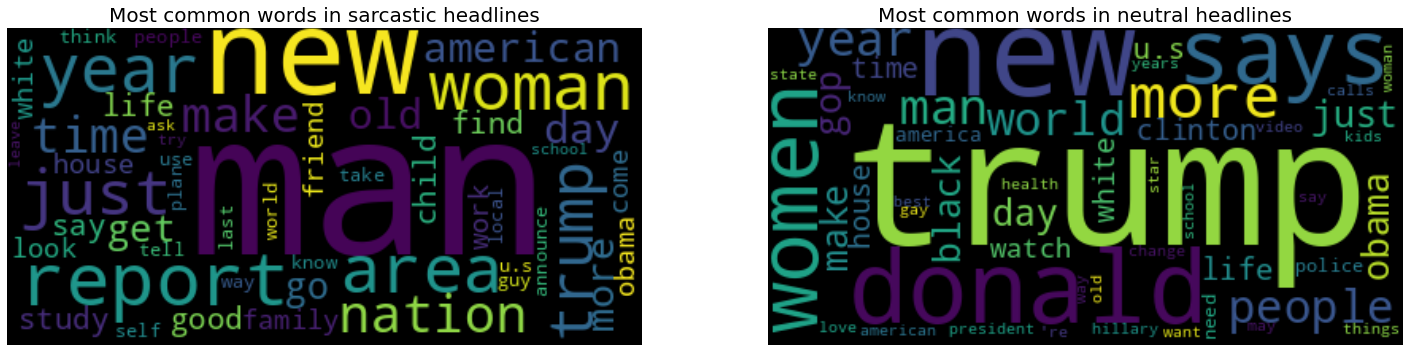

In [88]:
figure = plt.figure(figsize=(25, 25))
grid = gridspec.GridSpec(1, 2)

counter_sarcastic = Counter(tokens_sarcastic)
wordcloud_sarcastic = WordCloud(max_words=50).generate_from_frequencies(counter_sarcastic) 


counter_neutral = Counter(tokens_neutral)
wordcloud_neutral = WordCloud(max_words=50).generate_from_frequencies(counter_neutral)

sarcastic_overall = figure.add_subplot(grid[0, 0])
neutral_overall = figure.add_subplot(grid[0, 1])

sarcastic_overall.imshow(wordcloud_sarcastic, interpolation="bilinear")
sarcastic_overall.axis('off')
sarcastic_overall.set_title('Most common words in sarcastic headlines', fontdict={'fontsize': 20, 
                                                                                  'fontweight': 'medium'})
neutral_overall.imshow(wordcloud_neutral, interpolation="bilinear")
neutral_overall.axis('off')
neutral_overall.set_title('Most common words in neutral headlines', fontdict={'fontsize': 20, 
                                                                              'fontweight': 'medium'})

plt.show()

What we can see is that there are a few similarities: "trump", "man", "new", "woman" are common in both neutral and sarcastic headlines (all of them are in the top 5 most used words, see the table below). 

Another interesting thing we can notice is that neutral headlines tend to use politicians' first names more often ("Hillary", "Donald"), which is more formal than using the surname. Satirical newspapers tends to only use surnames, which is both informal and scornful. What's more, satirical news are less often about named individuals (such as Obama, Hilary Clinton or Donal Trump), and more about Mr and Mrs Smith (man, woman, american). 

Let's take a closer look to the repartition of the 25 most common words in both neutral and sarcastic headlines:

In [89]:
sorted_counter_sarcastic = dict(sorted(counter_sarcastic.items(), key=lambda item: item[1], reverse=True))
sarcastic_tokens_25 = list(sorted_counter_sarcastic.keys())[:25] 
sarcastic_count_25 = list(sorted_counter_sarcastic.values())[:25]

sorted_counter_neutral = dict(sorted(counter_neutral.items(), key=lambda item: item[1], reverse=True))
neutral_tokens_25 = list(sorted_counter_neutral.keys())[:25]
neutral_count_25 = list(sorted_counter_neutral.values())[:25]

counter_25 = {'sarcastic': sarcastic_tokens_25, 'count_sarcastic': sarcastic_count_25, 
              'neutral': neutral_tokens_25, 'count_neutral': neutral_count_25}

counter_sarcastic_df = pd.DataFrame(data=counter_25)
counter_sarcastic_df.head(25)

,sarcastic,count_sarcastic,neutral,count_neutral
0,man,1314,trump,1446
1,new,1007,new,680
2,report,576,donald,458
3,area,487,says,349
4,woman,485,women,305
5,year,472,more,296
6,just,438,year,244
7,trump,384,man,241
8,nation,378,people,241
9,make,363,world,241


#### Adjectives

Now on to the adjectives. The wordclouds and count comparisons do not provide much insights about the adjective usage: like for the most used tokens, we often find the same adjectives in both satirical and normal headlines, to various degrees. They can be found at the end of the notebook (appendice 1 a and b).

Nonetheless, satirical headlines contain more adjectives than their traditional counterparts (+171 adjectives). 

In [90]:
total_sarcastic_JJ = len(adjectives_sarcastic)
total_neutral_JJ = len(adjectives_neutral)

if total_sarcastic_JJ > total_neutral_JJ:
    print(f'There are more adjectives in sarcastic headlines (+{total_sarcastic_JJ - total_neutral_JJ}).')
elif total_sarcastic_JJ < total_neutral_JJ:
    print(f'There are more adjectives in neutral headlines (+{total_neutral_JJ - total_sarcastic_JJ}).')
else: 
    print('There is no difference in adjective usage.')

There are more adjectives in sarcastic headlines (+171).


Nevertheless, we can note that, in the given corpus, satirical news make extensive use of the adjective `new` (three times more used than the second most used adjective, `old`). One possible explanation might be that new things, like reforms, studies or tech items, tend to either build a hype or be highly controversial, but in any case, engross views and "new something ..." is a rather common headline nowadays. See appendice 1.c at the end for the most common bigrams of "new".

#### Nouns

There is nothing really interesting that comes out from the analysis of nouns usage (see appendice 2 at the end), except that satirical headlines tend to contain more words that feel "*closer to home*", such as "parents", "family", "house", "child", "friend" and "school", while traditional headlines contain more words like "health", "world, "life, "president", "police" and "state". 

Miscellaneous news items would use more words like those used in satirical headlines whereas more serious news require words such as used in the traditional headlines. Given that there are a lot more miscellaneous news items-like articles in newspapers like The Onion than in traditional newspaper, The Guardian for instance, this difference totally makes sense. 

#### Adverbs
    
While there was not a really significant difference how adjectives are used in traditional and satirical newspaper (15.628 adjectives in satirical headlines; 15.457 adjectives in traditional ones), adverbs are widely used in satirical newspapers (4.036 adverbs in sarcastic headlines and 2.325 in neutral headlines, an extra 1711 adverbs, almost twice as many).   

Adverbs are often found in stopwords lists, which could explain lower performances in a model where adverbs are removed for sarcasm detection. 

In [91]:
total_sarcastic_RB = len(adverbs_sarcastic)
total_neutral_RB = len(adverbs_neutral)

print(total_sarcastic_RB, total_neutral_RB)

if total_sarcastic_RB > total_neutral_RB:
    print(f'There are more adverbs in sarcastic headlines (+{total_sarcastic_RB - total_neutral_RB}).')
elif total_sarcastic_RB < total_neutral_RB:
    print(f'There are more adverbs in neutral headlines (+{total_neutral_RB - total_sarcastic_RB}).')
else: 
    print('There is no difference in adverbs usage.')

4036 2325
There are more adverbs in sarcastic headlines (+1711).


#### Recap

We find more adjectives and adverbs in sarcastic headlines than in neutral ones. Most common nouns in neutral headlines are more down-to-earth and serious, so to speak, as they reflect more what one expects from a newspaper: politics, health, national issues, while sarcastic headlines tend to contain more domestic-themed words, related to family. 

As a final analysis, here are pie chars of words repartitions according to their part of speech category in sarcastic and neutral headlines.

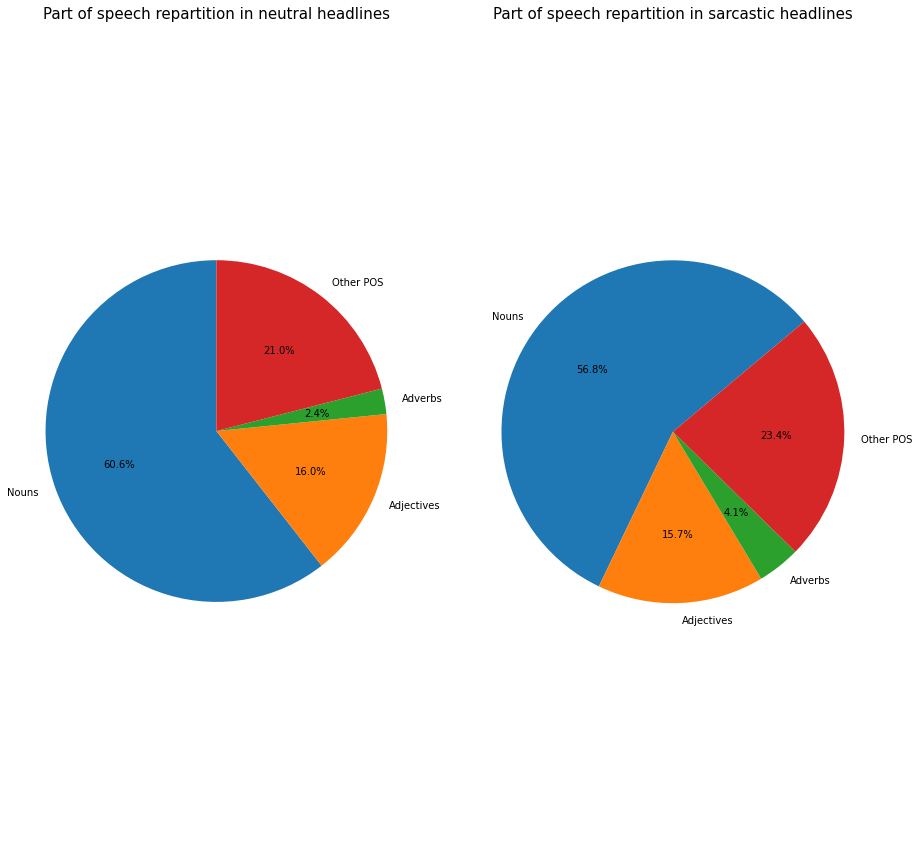

In [92]:
labels = ['Nouns', 'Adjectives', 'Adverbs', 'Other POS']
others_neutral = len(tokens_neutral) - len(nouns_neutral) - len(adjectives_neutral) - len(adverbs_neutral)
neutral = [len(nouns_neutral), len(adjectives_neutral), len(adverbs_neutral), others_neutral]
others_sarcastic = len(tokens_sarcastic) - len(nouns_sarcastic) 
# split the soustraction for readability, else the line would be too long
others_sarcastic = others_sarcastic - len(adjectives_sarcastic) - len(adverbs_sarcastic)
sarcastic = [len(nouns_sarcastic), len(adjectives_sarcastic), len(adverbs_sarcastic), others_sarcastic] 

figure = plt.figure(figsize=(15, 15))
grid = gridspec.GridSpec(1, 2)

neutral_pie = figure.add_subplot(grid[0, 0])
sarcastic_pie = figure.add_subplot(grid[0,1])

neutral_pie.pie(neutral, labels=labels, autopct='%1.1f%%',
        shadow=False, startangle=90)
neutral_pie.axis('equal')
neutral_pie.set_title('Part of speech repartition in neutral headlines', fontdict={'fontsize': 15, 
                                                                                  'fontweight': 'medium'})

sarcastic_pie.pie(sarcastic, labels=labels, autopct='%1.1f%%',
        shadow=False, startangle=40)
sarcastic_pie.axis('equal')
sarcastic_pie.set_title('Part of speech repartition in sarcastic headlines', fontdict={'fontsize': 15, 
                                                                                  'fontweight': 'medium'})

plt.show()

## Building the models 

As mention earlier, we will try buidling models with no processing done to the text at all, without punctuations and stopwords and with lemmas only. 

Before diving into neural network architecture, we will also try a simple Linear Regression and a Multinomial Naive Bayes models, with bags of words (CountVectorizer) and TF-IDF. 

We'll start with bags of words.

In [93]:
# splitting the data according to a 70/30 ratio
test_samples = 8551
training_samples = 19952

For our baseline models, we'll use scikit-learn instead of keras, so we'll import what we need here. 

### Bags of words

#### Linear regression

##### No processing

In [94]:
from nltk.tokenize import word_tokenize
from sklearn import linear_model
from sklearn import metrics
from sklearn import naive_bayes
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

vectorizer = CountVectorizer(tokenizer=word_tokenize, token_pattern=None)
transformed_headlines = vectorizer.fit_transform(sarcasm_dataframe.headline)

X_train = transformed_headlines[:training_samples]
y_train = list(sarcasm_dataframe.is_sarcastic)[:training_samples]
X_test = transformed_headlines[training_samples: training_samples + test_samples]
y_test = list(sarcasm_dataframe.is_sarcastic[training_samples: training_samples + test_samples])

model = linear_model.LogisticRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)
accuracy = metrics.accuracy_score(y_test, predictions)
print(accuracy)

0.8567419015319846


We reach a pretty good results (85.67%) with minimal efforts (the dataset's authors reached 84.88% with their baseline, 89.7% with their proposed model[1]). 

##### No stopwords

In [96]:
transformed_headlines = vectorizer.fit_transform(sarcasm_dataframe.headline_tokens)

X_train = transformed_headlines[:training_samples]
y_train = list(sarcasm_dataframe.is_sarcastic)[:training_samples]
X_test = transformed_headlines[training_samples: training_samples + test_samples]
y_test = list(sarcasm_dataframe.is_sarcastic[training_samples: training_samples + test_samples])

model = linear_model.LogisticRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)
accuracy = metrics.accuracy_score(y_test, predictions)
print(accuracy)

0.7953455736171208


We can see a pretty significant drop in performance already (-6.14%), which might be linked to the presence of adverbs in the stopwords list, since we saw that adverbs is rather distinctive of sarcastic headlines. However, we would need to carry further analysis of the misclassified examples to explain what is really going on, via a confusion matrix for instance. 

##### Lemmas

In [97]:
transformed_headlines = vectorizer.fit_transform(sarcasm_dataframe.headline_lemmas)

X_train = transformed_headlines[:training_samples]
y_train = list(sarcasm_dataframe.is_sarcastic)[:training_samples]
X_test = transformed_headlines[training_samples: training_samples + test_samples]
y_test = list(sarcasm_dataframe.is_sarcastic[training_samples: training_samples + test_samples])

model = linear_model.LogisticRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)
accuracy = metrics.accuracy_score(y_test, predictions)
print(accuracy)

0.7870424511753011


As expected, with lemmas, the accuracy drops even more than without punctuation and stopwords.

To conclude with linear regression X bags of word, the best model is the one with the full headlines tokenized. 

#### Multinomial Naives Bayes

##### No processing

In [107]:
model = naive_bayes.MultinomialNB()

transformed_headlines = vectorizer.fit_transform(sarcasm_dataframe.headline)

X_train = transformed_headlines[:training_samples]
y_train = list(sarcasm_dataframe.is_sarcastic)[:training_samples]
X_test = transformed_headlines[training_samples: training_samples + test_samples]
y_test = list(sarcasm_dataframe.is_sarcastic[training_samples: training_samples + test_samples])

model.fit(X_train, y_train)
predictions = model.predict(X_test)
accuracy = metrics.accuracy_score(y_test, predictions)
print(accuracy)

0.8650450239738042


So far, Multinomial Naive Bayes associated to bags of words is our best model, with 86.50% accuracy (+0.83%). Let's see if the processing done increase or decrease the accuracy of the model.

##### No stopwords

In [108]:
transformed_headlines = vectorizer.fit_transform(sarcasm_dataframe.headline_tokens)

X_train = transformed_headlines[:training_samples]
y_train = list(sarcasm_dataframe.is_sarcastic)[:training_samples]
X_test = transformed_headlines[training_samples: training_samples + test_samples]
y_test = list(sarcasm_dataframe.is_sarcastic[training_samples: training_samples + test_samples])

model = naive_bayes.MultinomialNB()
model.fit(X_train, y_train)
predictions = model.predict(X_test)
accuracy = metrics.accuracy_score(y_test, predictions)
print(accuracy)

0.8004911706233189


Here again, we notice a drop in performance (-6.46%)

#### Lemmas

In [109]:
transformed_headlines = vectorizer.fit_transform(sarcasm_dataframe.headline_lemmas)

X_train = transformed_headlines[:training_samples]
y_train = list(sarcasm_dataframe.is_sarcastic)[:training_samples]
X_test = transformed_headlines[training_samples: training_samples + test_samples]
y_test = list(sarcasm_dataframe.is_sarcastic[training_samples: training_samples + test_samples])

model = naive_bayes.MultinomialNB()
model.fit(X_train, y_train)
predictions = model.predict(X_test)
accuracy = metrics.accuracy_score(y_test, predictions)
print(accuracy)

0.7932405566600398


Just like with the linear regression, using the lemmatized forms of the headline gives poorer results than the other two alternatives. We can conclude that we lose important features of sarcasm and/or differences in how the words are used in sarcastic and non sarcastic newspapers when using lemmatization.

### TF-IDF

#### Linear regression

##### No processing

In [110]:
tfidf = TfidfVectorizer(tokenizer=word_tokenize, token_pattern=None)
transformed_headlines = tfidf.fit_transform(sarcasm_dataframe.headline)

X_train = transformed_headlines[:training_samples]
y_train = list(sarcasm_dataframe.is_sarcastic)[:training_samples]
X_test = transformed_headlines[training_samples: training_samples + test_samples]
y_test = list(sarcasm_dataframe.is_sarcastic[training_samples: training_samples + test_samples])

model = linear_model.LogisticRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)
accuracy = metrics.accuracy_score(y_test, predictions)
print(accuracy)

0.8593147000350836


There is a slight improvement compared to its bags of words counterpart, but nothing really significant (+0.26). 

##### No stopwords

In [111]:
transformed_headlines = tfidf.fit_transform(sarcasm_dataframe.headline_tokens)

X_train = transformed_headlines[:training_samples]
y_train = list(sarcasm_dataframe.is_sarcastic)[:training_samples]
X_test = transformed_headlines[training_samples: training_samples + test_samples]
y_test = list(sarcasm_dataframe.is_sarcastic[training_samples: training_samples + test_samples])

model = linear_model.LogisticRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)
accuracy = metrics.accuracy_score(y_test, predictions)
print(accuracy)

0.7910185943164543


##### Lemmas

In [112]:
transformed_headlines = tfidf.fit_transform(sarcasm_dataframe.headline_lemmas)

X_train = transformed_headlines[:training_samples]
y_train = list(sarcasm_dataframe.is_sarcastic)[:training_samples]
X_test = transformed_headlines[training_samples: training_samples + test_samples]
y_test = list(sarcasm_dataframe.is_sarcastic[training_samples: training_samples + test_samples])

model = linear_model.LogisticRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)
accuracy = metrics.accuracy_score(y_test, predictions)
print(accuracy)

0.7845865980587066


#### Multinomial Naive Bayes

##### No processing

In [113]:
transformed_headlines = tfidf.fit_transform(sarcasm_dataframe.headline)

X_train = transformed_headlines[:training_samples]
y_train = list(sarcasm_dataframe.is_sarcastic)[:training_samples]
X_test = transformed_headlines[training_samples: training_samples + test_samples]
y_test = list(sarcasm_dataframe.is_sarcastic[training_samples: training_samples + test_samples])

model = linear_model.LogisticRegression()

model = naive_bayes.MultinomialNB()
model.fit(X_train, y_train)
predictions = model.predict(X_test)
accuracy = metrics.accuracy_score(y_test, predictions)
print(accuracy)

0.8448134721085253


##### No stopwords

In [114]:
transformed_headlines = tfidf.fit_transform(sarcasm_dataframe.headline_tokens)

X_train = transformed_headlines[:training_samples]
y_train = list(sarcasm_dataframe.is_sarcastic)[:training_samples]
X_test = transformed_headlines[training_samples: training_samples + test_samples]
y_test = list(sarcasm_dataframe.is_sarcastic[training_samples: training_samples + test_samples])

model = naive_bayes.MultinomialNB()
model.fit(X_train, y_train)
predictions = model.predict(X_test)
accuracy = metrics.accuracy_score(y_test, predictions)
print(accuracy)

0.7986200444392468


##### Lemmas

In [106]:
transformed_headlines = tfidf.fit_transform(sarcasm_dataframe.headline_lemmas)

X_train = transformed_headlines[:training_samples]
y_train = list(sarcasm_dataframe.is_sarcastic)[:training_samples]
X_test = transformed_headlines[training_samples: training_samples + test_samples]
y_test = list(sarcasm_dataframe.is_sarcastic[training_samples: training_samples + test_samples])

model = naive_bayes.MultinomialNB()
model.fit(X_train, y_train)
predictions = model.predict(X_test)
accuracy = metrics.accuracy_score(y_test, predictions)
print(accuracy)

0.7868085604022921


The same trend than before can be observed: the best performing model is the one where the data is barely processed at all (only tokenization is performed). However, compared to its bags of words counterpart, the Multinomial Naive Bayes with tf-idf vectorization performs slightly worse (-2.01%). 

### Neural network architectures

With these, we have several baselines against which we will be able to compared our neural network architectures.
Like before, we will try with all three kinds of processing: it is expected that the one with barely no processing at all will perform better than the other two. 

We'll try out two neural network architecture: one with only Dense neurons, and Bi-LSTM networks. Because they are sequence to sequence models and can capture long-term dependencies between sequences, they are well suited for natural language processing tasks. 

We will also work with a callback to restore the best epoch, to avoid overfitting as it is expected to happen rather quickly. 

***Note***: *the models found in the notebook don't used pretrained word vectors such as glove, but one can be found in the repository as well.*

In [69]:
# defining functions to repeat the model architecture for the different tests
def build_dense(name):
    model = Sequential(name=name)
    model.add(Embedding(max_words, embedding_dim, input_length=max_len))
    model.add(Flatten())
    model.add(Dense(128, activation='relu'))
    model.add(Dense(64, activation='relu'))
    model.add(Dense(32, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))
    model.summary()
    model.compile(loss='binary_crossentropy', optimizer='adam', 
                    metrics=['accuracy'])
    return model


def build_bilstm(name):
    model = Sequential(name=name)
    model.add(Embedding(max_words, embedding_dim, input_length=max_len))
    model.add(Dropout(0.2))
    model.add(Bidirectional(LSTM(64, dropout=0.2, return_sequences=True)))
    model.add(Bidirectional(LSTM(32, dropout=0.2, return_sequences=True)))
    model.add(GlobalAveragePooling1D())
    model.add(Dense(256, activation='relu'))
    model.add(Dropout(0.2))
    model.add(Dense(128, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))
    model.summary()
    model.compile(loss='binary_crossentropy', optimizer='adam', 
                    metrics=['accuracy'])
    
    return model


# plotting loss during training 
def plot_accuracy(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    epochs = range(1, len(acc) + 1)

    plt.plot(epochs, acc, 'bo', label='Training accuracy')
    plt.plot(epochs, val_acc, 'b', label='Validation accuracy')
    plt.title('Training and validation accuracy')
    plt.legend()

    plt.figure()

    plt.plot(epochs, loss, 'bo', label='Training loss')
    plt.plot(epochs, val_loss, 'b', label='Validation loss')
    plt.title('Training and validation loss')
    plt.legend()

    plt.show()

    
# defining model parameters
max_len = 32
embedding_dim = 300
max_words = 25000


callback = EarlyStopping(
    monitor="val_accuracy",
    patience=5,
    verbose=1,
    restore_best_weights=True,
)

# defining the data according to the level of processing
labels = np.asarray(sarcasm_dataframe.is_sarcastic)
## no processing
tokenizer_one = Tokenizer(num_words=max_words)
tokenizer_one.fit_on_texts(sarcasm_dataframe.headline)
sequences_one = tokenizer_one.texts_to_sequences(sarcasm_dataframe.headline)

data_one = pad_sequences(sequences_one, maxlen=max_len)

X_train_one = data_one[:training_samples]
y_train_one = labels[:training_samples]
X_test_one = data_one[training_samples: training_samples + test_samples]
y_test_one = labels[training_samples: training_samples + test_samples]

# lemmas
tokenizer_two = Tokenizer(num_words=max_words)
tokenizer_two.fit_on_texts(sarcasm_dataframe.headline_lemmas)
sequences_two = tokenizer_two.texts_to_sequences(sarcasm_dataframe.headline_lemmas)

data_two = pad_sequences(sequences_two, maxlen=max_len)

X_train_two = data_two[:training_samples]
y_train_two = labels[:training_samples]
X_test_two = data_two[training_samples: training_samples + test_samples]
y_test_two = labels[training_samples: training_samples + test_samples]

# no stopwords
tokenizer_three = Tokenizer(num_words=max_words)
tokenizer_three.fit_on_texts(sarcasm_dataframe.headline_tokens)
sequences_three = tokenizer_three.texts_to_sequences(sarcasm_dataframe.headline_tokens)

data_three = pad_sequences(sequences_three, maxlen=max_len)

X_train_three = data_one[:training_samples]
y_train_three = labels[:training_samples]
X_test_three = data_one[training_samples: training_samples + test_samples]
y_test_three = labels[training_samples: training_samples + test_samples]

### Dense

#### No processing

Model: "Dense-no-processing"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_16 (Embedding)     (None, 32, 300)           7500000   
_________________________________________________________________
flatten_5 (Flatten)          (None, 9600)              0         
_________________________________________________________________
dense_53 (Dense)             (None, 128)               1228928   
_________________________________________________________________
dense_54 (Dense)             (None, 64)                8256      
_________________________________________________________________
dense_55 (Dense)             (None, 32)                2080      
_________________________________________________________________
dense_56 (Dense)             (None, 1)                 33        
Total params: 8,739,297
Trainable params: 8,739,297
Non-trainable params: 0
_____________________________________

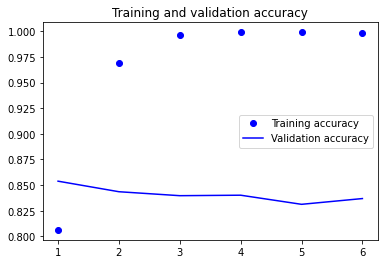

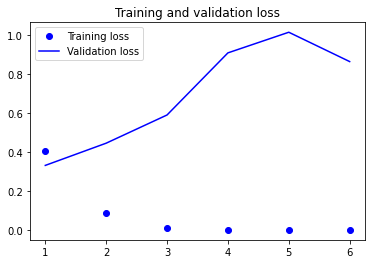

In [115]:
model = build_dense('Dense-no-processing')
history = model.fit(X_train_one, y_train_one, epochs=10, batch_size=32, 
                    validation_data=(X_test_one, y_test_one), callbacks=[callback])

plot_accuracy(history)

##### No stopwords

Model: "No-stopwords"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_17 (Embedding)     (None, 32, 300)           7500000   
_________________________________________________________________
flatten_6 (Flatten)          (None, 9600)              0         
_________________________________________________________________
dense_57 (Dense)             (None, 128)               1228928   
_________________________________________________________________
dense_58 (Dense)             (None, 64)                8256      
_________________________________________________________________
dense_59 (Dense)             (None, 32)                2080      
_________________________________________________________________
dense_60 (Dense)             (None, 1)                 33        
Total params: 8,739,297
Trainable params: 8,739,297
Non-trainable params: 0
____________________________________________

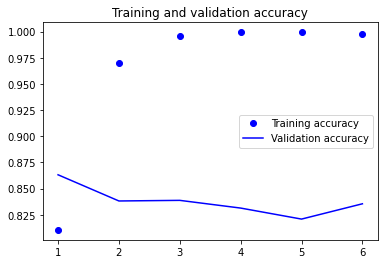

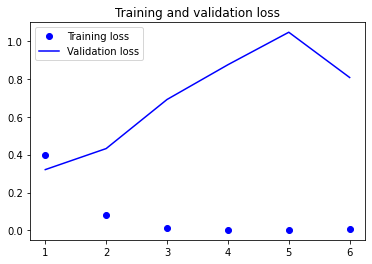

In [116]:
model = build_dense('No-stopwords')
history = model.fit(X_train_three, y_train_three, epochs=10, batch_size=32, 
                    validation_data=(X_test_three, y_test_three), callbacks=[callback])
plot_accuracy(history)

##### Lemmas

Model: "Lemmas"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_18 (Embedding)     (None, 32, 300)           7500000   
_________________________________________________________________
flatten_7 (Flatten)          (None, 9600)              0         
_________________________________________________________________
dense_61 (Dense)             (None, 128)               1228928   
_________________________________________________________________
dense_62 (Dense)             (None, 64)                8256      
_________________________________________________________________
dense_63 (Dense)             (None, 32)                2080      
_________________________________________________________________
dense_64 (Dense)             (None, 1)                 33        
Total params: 8,739,297
Trainable params: 8,739,297
Non-trainable params: 0
__________________________________________________

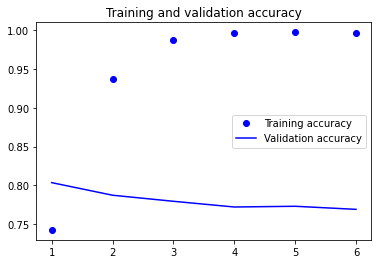

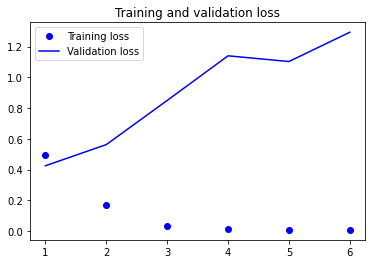

In [117]:
model = build_dense('Lemmas')
history = model.fit(X_train_two, y_train_two, epochs=10, batch_size=32, 
                    validation_data=(X_test_two, y_test_two), callbacks=[callback])
plot_accuracy(history)

#### Bi-LSTM

Model: "Bi-LSTM-No-processing"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_19 (Embedding)     (None, 32, 300)           7500000   
_________________________________________________________________
dropout_22 (Dropout)         (None, 32, 300)           0         
_________________________________________________________________
bidirectional_18 (Bidirectio (None, 32, 128)           186880    
_________________________________________________________________
bidirectional_19 (Bidirectio (None, 32, 64)            41216     
_________________________________________________________________
global_average_pooling1d_11  (None, 64)                0         
_________________________________________________________________
dense_65 (Dense)             (None, 256)               16640     
_________________________________________________________________
dropout_23 (Dropout)         (None, 256)     

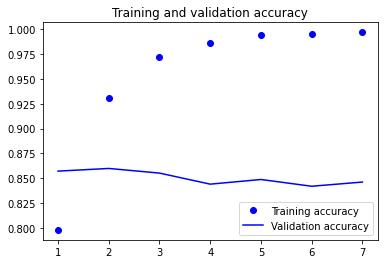

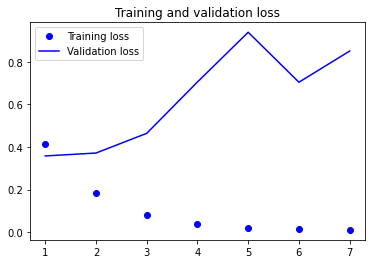

In [118]:
model = build_bilstm('Bi-LSTM-No-processing')
history = model.fit(X_train_one, y_train_one, epochs=10, batch_size=32, 
                    validation_data=(X_test_one, y_test_one), callbacks=[callback])
plot_accuracy(history)

Model: "Bi-LSTM-No-stopwords"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_20 (Embedding)     (None, 32, 300)           7500000   
_________________________________________________________________
dropout_24 (Dropout)         (None, 32, 300)           0         
_________________________________________________________________
bidirectional_20 (Bidirectio (None, 32, 128)           186880    
_________________________________________________________________
bidirectional_21 (Bidirectio (None, 32, 64)            41216     
_________________________________________________________________
global_average_pooling1d_12  (None, 64)                0         
_________________________________________________________________
dense_68 (Dense)             (None, 256)               16640     
_________________________________________________________________
dropout_25 (Dropout)         (None, 256)      

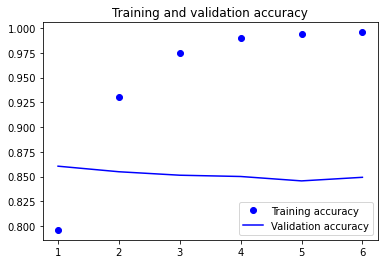

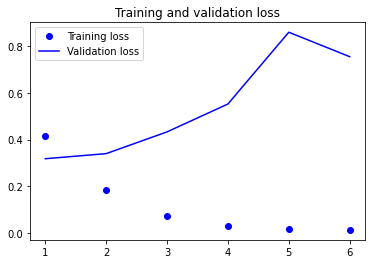

In [119]:
model = build_bilstm('Bi-LSTM-No-stopwords')
history = model.fit(X_train_three, y_train_three, epochs=15, batch_size=32, 
                    validation_data=(X_test_three, y_test_three), callbacks=[callback])
plot_accuracy(history)

Model: "Bi-LSTM-Lemmas"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_21 (Embedding)     (None, 32, 300)           7500000   
_________________________________________________________________
dropout_26 (Dropout)         (None, 32, 300)           0         
_________________________________________________________________
bidirectional_22 (Bidirectio (None, 32, 128)           186880    
_________________________________________________________________
bidirectional_23 (Bidirectio (None, 32, 64)            41216     
_________________________________________________________________
global_average_pooling1d_13  (None, 64)                0         
_________________________________________________________________
dense_71 (Dense)             (None, 256)               16640     
_________________________________________________________________
dropout_27 (Dropout)         (None, 256)            

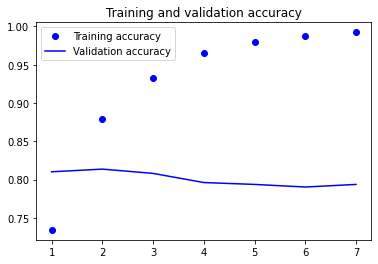

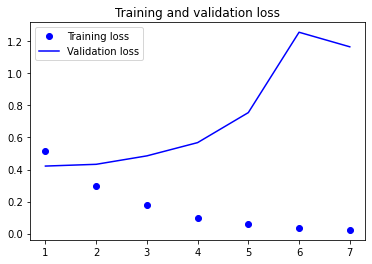

In [120]:
model = build_bilstm('Bi-LSTM-Lemmas')
history = model.fit(X_train_two, y_train_two, epochs=15, batch_size=32, 
                    validation_data=(X_test_two, y_test_two), callbacks=[callback])
plot_accuracy(history)

### Comparing the models

Overall, we observed that the models where no processing was performed on the data have slightly better results than those where some processing was done. 

|               | Logistic Regression +  BoW  | MultinomialNB + BoW  | Logistic Regression + TF-IDF | MultinomialNB + TF-IDF | Dense | BiLSTM |
|---------------|-----------------------------|----------------------|------------------------------|------------------------|-------|--------|
| No processing | 85.67                       | **86.50**            | 85.93                        | 84.48                  | 83.69 | 84.62  |
| No stopwords  | 79.53                       | 80.04                | 79.10                        | 79.86                  | 83.55 | 84.93  |
| Lemmas        | 78.70                       | 79.32                | 78.45                        | 78.68                  | 76.90 | 79.36  |

Those performing the worst are the ones which were fed lemmatized lemmas. As already supposed, important features of sarcasm are lost when words are lemmatized.

The model with the bests result is the Multinomial Naive Bayes with bag of words model (no preprocessing), followed by the Logistic Regression with TF-IDF model (no preprocessing). 

## Appendices

### 1. Adjectives wordcloud and count comparison

In [124]:
counter_neutral_JJ = Counter(adjectives_neutral)
counter_sarcastic_JJ = Counter(adjectives_sarcastic)

#### (a) Most common adjectives, wordclouds (50)

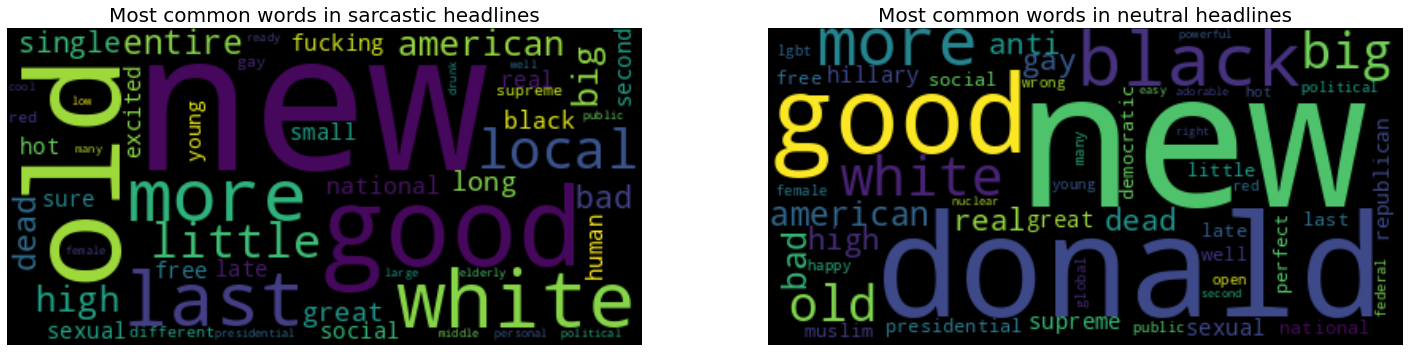

In [125]:
figure = plt.figure(figsize=(25, 25))
grid = gridspec.GridSpec(1, 2)

wordcloud_sarcastic_JJ = WordCloud(max_words=50).generate_from_frequencies(counter_sarcastic_JJ) 
wordcloud_neutral_JJ = WordCloud(max_words=50).generate_from_frequencies(counter_neutral_JJ)

sarcastic_JJ = figure.add_subplot(grid[0, 0])
neutral_JJ = figure.add_subplot(grid[0, 1])

sarcastic_JJ.imshow(wordcloud_sarcastic_JJ, interpolation="bilinear")
sarcastic_JJ.axis('off')
sarcastic_JJ.set_title('Most common words in sarcastic headlines', fontdict={'fontsize': 20, 
                                                                                  'fontweight': 'medium'})
neutral_JJ.imshow(wordcloud_neutral_JJ, interpolation="bilinear")
neutral_JJ.axis('off')
neutral_JJ.set_title('Most common words in neutral headlines', fontdict={'fontsize': 20, 
                                                                          'fontweight': 'medium'})
plt.show()

####  (b) Most common adjectives, table (25)

In [126]:
sorted_counter_sarcastic = dict(sorted(counter_sarcastic_JJ.items(), key=lambda item: item[1], reverse=True))
sorted_counter_neutral = dict(sorted(counter_neutral_JJ.items(), key=lambda item: item[1], reverse=True))

sarcastic_adjectives_25 = list(sorted_counter_sarcastic.keys())[:25]
sarcastic_count_25 = list(sorted_counter_sarcastic.values())[:25]

neutral_adjectives_25 = list(sorted_counter_neutral.keys())[:25]
neutral_count_25 = list(sorted_counter_neutral.values())[:25]

counter_25 = {'sarcastic': sarcastic_adjectives_25, 'count_sarcastic': sarcastic_count_25, 
              'neutral': neutral_adjectives_25, 'count_neutral': neutral_count_25}

counter_sarcastic_df = pd.DataFrame(data=counter_25)
counter_sarcastic_df.head(25)

,sarcastic,count_sarcastic,neutral,count_neutral
0,new,1006,new,686
1,old,316,donald,438
2,good,219,good,245
3,white,189,black,203
4,last,174,more,190
5,more,169,white,186
6,local,158,big,167
7,little,143,old,160
8,american,124,american,141
9,high,120,bad,140


#### (c) Most common ngrams with the adjective "new" in satirical headlines

Here, bigrams are used, but it can be changed to bigger ngrams by changing the `n` argument.

In [127]:
exclude_pattern = r' \bnew\b (?!york|orleans?|jersey|hampshire|\d+)'
headlines = list(sarcasm_dataframe.loc[sarcasm_dataframe['is_sarcastic'] == 1, 'headline_lemmas'])
headlines_with_new = [headline for headline in headlines if re.search(exclude_pattern, headline)]

def new_ngrams(headline, n=2):
    split_headline = headline.split()
    starting_index = split_headline.index('new')
    return " ".join(split_headline[starting_index:starting_index + n])

ngrams = []
for headline in headlines_with_new:
    try: 
        ngram = new_ngrams(headline)
        ngrams.append(ngram)
    except ValueError:
        continue
        
print(Counter(ngrams).most_common(25))

[('new line', 22), ('new job', 7), ('new video', 5), ('new girlfriend', 5), ('new drug', 4), ('new way', 4), ('new year', 4), ('new high', 4), ('new double', 3), ('new thing', 3), ('new low', 3), ('new pope', 3), ('new specie', 3), ('new book', 3), ('new evidence', 3), ('new song', 3), ('new law', 3), ('new air', 3), ('new hobby', 3), ('new sport', 2), ('new life', 2), ('new beach', 2), ('new meat', 2), ('new window', 2), ('new phase', 2)]


### 2. Nouns wordcloud and count comparison

In [139]:
counter_neutral_NN = Counter(nouns_neutral)
counter_sarcastic_NN = Counter(nouns_sarcastic)

#### (a) Most common nouns, wordcloud (50)

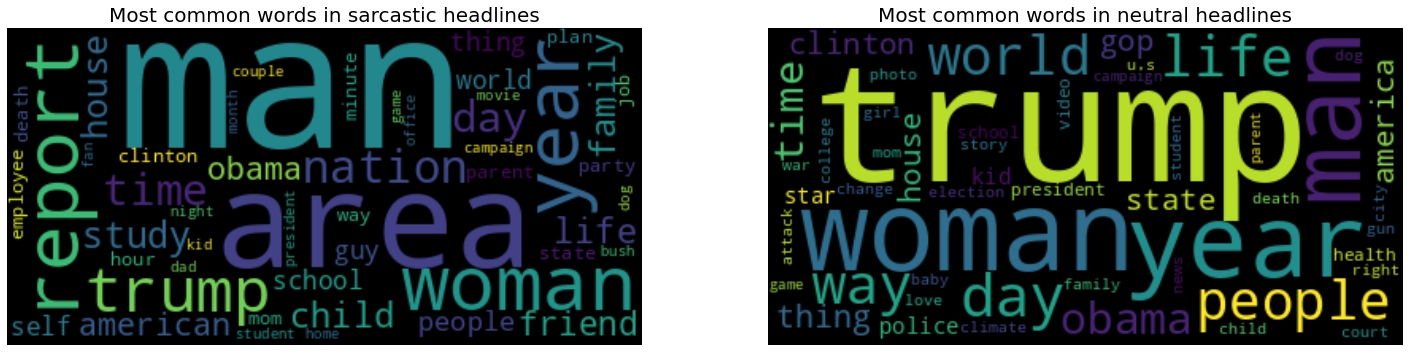

In [130]:
figure = plt.figure(figsize=(25, 25))
grid = gridspec.GridSpec(1, 2)

wordcloud_neutral_NN = WordCloud(max_words=50).generate_from_frequencies(counter_neutral_NN)
wordcloud_sarcastic_NN = WordCloud(max_words=50).generate_from_frequencies(counter_sarcastic_NN)

sarcastic_NN = figure.add_subplot(grid[0, 0])
neutral_NN = figure.add_subplot(grid[0, 1])

sarcastic_NN.imshow(wordcloud_sarcastic_NN, interpolation="bilinear")
sarcastic_NN.axis('off')
sarcastic_NN.set_title('Most common words in sarcastic headlines', fontdict={'fontsize': 20, 
                                                                                  'fontweight': 'medium'})
neutral_NN.imshow(wordcloud_neutral_NN, interpolation="bilinear")
neutral_NN.axis('off')
neutral_NN.set_title('Most common words in neutral headlines', fontdict={'fontsize': 20, 
                                                                              'fontweight': 'medium'})

plt.show()

#### (b) Most common nouns, table (25)

In [131]:
sorted_counter_sarcastic = dict(sorted(counter_sarcastic_NN.items(), key=lambda item: item[1], reverse=True))
sarcastic_tokens_25 = list(sorted_counter_sarcastic.keys())[:25] 
sarcastic_count_25 = list(sorted_counter_sarcastic.values())[:25]

sorted_counter_neutral = dict(sorted(counter_neutral_NN.items(), key=lambda item: item[1], reverse=True))
neutral_tokens_25 = list(sorted_counter_neutral.keys())[:25]
neutral_count_25 = list(sorted_counter_neutral.values())[:25]

counter_25 = {'sarcastic': sarcastic_tokens_25, 'count_sarcastic': sarcastic_count_25, 
              'neutral': neutral_tokens_25, 'count_neutral': neutral_count_25}

counter_sarcastic_df = pd.DataFrame(data=counter_25)
counter_sarcastic_df.head(25)

,sarcastic,count_sarcastic,neutral,count_neutral
0,man,1303,trump,1408
1,area,486,woman,467
2,woman,485,year,381
3,report,482,man,344
4,year,472,day,269
5,trump,382,way,247
6,nation,378,life,247
7,time,358,people,243
8,day,342,world,242
9,study,244,obama,240


### 3. Adverbs

In [137]:
counter_neutral_RB = Counter(adverbs_neutral)
counter_sarcastic_RB = Counter(adverbs_sarcastic)

In [138]:
sorted_counter_sarcastic = dict(sorted(counter_sarcastic_RB.items(), key=lambda item: item[1], reverse=True))
sorted_counter_neutral = dict(sorted(counter_neutral_RB.items(), key=lambda item: item[1], reverse=True))

sarcastic_adverbs_25 = list(sorted_counter_sarcastic.keys())[:25]
sarcastic_count_25 = list(sorted_counter_sarcastic.values())[:25]

neutral_adverbs_25 = list(sorted_counter_neutral.keys())[:25]
neutral_count_25 = list(sorted_counter_neutral.values())[:25]

counter_25 = {'sarcastic': sarcastic_adverbs_25, 'count_sarcastic': sarcastic_count_25, 
              'neutral': neutral_adverbs_25, 'count_neutral': neutral_count_25}

counter_sarcastic_df = pd.DataFrame(data=counter_25)
counter_sarcastic_df.head(25)

,sarcastic,count_sarcastic,neutral,count_neutral
0,just,436,just,236
1,really,132,really,121
2,more,123,more,106
3,never,123,never,75
4,finally,95,actually,66
5,pretty,90,finally,57
6,actually,81,reportedly,45
7,away,79,away,40
8,right,75,long,39
9,clearly,56,probably,39


## References

[1] 
- Misra, R., Arora, P. (2019). Sarcasm Detection using Hybrid Neural Network. arXiv preprint arXiv:1908.07414  
- Misra, R. Grover, J. (2021). Sculpting Data for ML: The first act of Machine Learning. 978-0-578-83125-1

[2] (2021). Definition of sarcasm [online]. Oxford University Press. Available at: https://www.lexico.com/definition/sarcasm (Accessed: 03 May 2021).

[3] (2021). Definition of sarcasm [online]. Oxford University Press. Available at: https://www.lexico.com/definition/irony (Accessed: 03 May 2021).

[4] (n.d). Definition of satire [online]. Upstate, University of South Carolina. Retrieved 10 May 2021 at : https://uscupstate.libguides.com/news_aware/SatireNews

[5] Rubin, V. L., Conroy, N., Chen, Y., & Cornwell, S. (2016, June). Fake news or truth? using satirical cues to detect potentially misleading news. In Proceedings of the second workshop on computational approaches to deception detection (pp. 7).

This notebook was authored by Eulalie Monget, in April 2021.